In [3]:
# cargamos los datos de la API

import requests
import pandas as pd

url = "https://api.bcra.gob.ar/estadisticas/v4.0/monetarias/27"
r=requests.get(url, params={"desde":"2017-01-01","hasta": "2026-09-30"})
r.status_code # 200 si sale bien, 404 o 500 si no

200

In [4]:
datos=r.json()["results"][0]["detalle"] # json convierte en estructuras que Python lee
# detalles es la listas de pares fecha-valor
df=pd.DataFrame(datos) # convierte lista en tabla de pares, fecha y valor quedan como columnas
df["fecha"]=pd.to_datetime(df["fecha"])
df=df.sort_values("fecha").reset_index(drop=True) # fechas de mas antigua a mas reciente y desechamos las viejas enumeraciones
df.head()


,fecha,valor
0,2017-01-31,1.3
1,2017-02-28,2.5
2,2017-03-31,2.4
3,2017-04-30,2.6
4,2017-05-31,1.3


In [5]:
print(df.shape)
print(df.dtypes)
print(df["valor"].isna().sum())
print(df["fecha"].is_monotonic_increasing) # la fecha va subiendo? esperamos True

(117, 2)
fecha    datetime64[ns]
valor           float64
dtype: object
0
True


In [6]:
from pathlib import Path

Path("../data/raw").mkdir(parents=True, exist_ok=True)
df.to_csv("../data/raw/bcra_inflacion_mensual.csv", index=False)

In [7]:
pd.read_csv("../data/raw/bcra_inflacion_mensual.csv").tail()

,fecha,valor
112,2026-05-31,2.1
113,2026-06-30,1.9
114,2026-07-31,2.1
115,2026-08-31,1.7
116,2026-09-30,1.9


In [8]:
def descargar_serie(id_variable, desde, hasta):
    url = f"https://api.bcra.gob.ar/estadisticas/v4.0/monetarias/{id_variable}"
    limite = 1000
    offset = 0 # porque sino la serie del fx se corta en 1000, llamamos por tandas
    filas = []
    while True:
        r = requests.get(url, params={"desde": desde, "hasta": hasta,
                                      "limit": limite, "offset": offset})
        r.raise_for_status() # a ver si salió bien
        detalle = r.json()["results"][0]["detalle"]
        filas.extend(detalle)
        if len(detalle) < limite:
            break
        offset += limite
    df = pd.DataFrame(filas)
    df["fecha"] = pd.to_datetime(df["fecha"])
    return df.sort_values("fecha").reset_index(drop=True)


In [9]:
df2 = descargar_serie(27, "2017-01-01", "2026-09-30")
df2.shape

(117, 2)

In [10]:
# el TC mayorista es con el que comercian bancos y empresas (minorista=mayorista+margen), y en Argentina
# es importante para analizar la inflación por el pass-through (efecto del cambio en TC en los precios internos)

# con la serie diaria tenemos los datos de todo el mes, y como pronosticamos despues de que el mes haya
# terminado, conocemos el TC de todos esos dias aunque el INDEC no haya publicado el IPC. Es 
# la ventaja informativa del nowcast.

fx=descargar_serie(5, "2017-01-01", "2026-11-03")
print(fx.shape)
print(fx["fecha"].min(), fx["fecha"].max())

(2391, 2)
2017-01-02 00:00:00 2026-11-03 00:00:00


In [11]:
# BADLAR: es la tasa que pagan los bancos privados por plazos fijos grandes. Es una medida de las condiciones
# monetarias en pesos y de lo que el mercado espera. Si los ahorristas piden tasas más altas, suele ser 
# porque esperan más inflación o más depreciación. Además, comparada con la inflación, da la tasa real: si la 
# tasa queda por debajo de lo que sube el costo de vida, hay presión hacia el dólar.

series={
    "tc_mayorista":5,
    "badlar_nominal":7,
    "reservas":1,
    "inflacion_mensual":27
}

for nombre, id_variable in series.items():
    d=descargar_serie(id_variable, "2017-01-01", "2026-11-03")
    d.to_csv(f"../data/raw/bcra_{nombre}.csv", index=False)
    print(nombre, d.shape, d["fecha"].min().date(), d["fecha"].max().date(),
          "duplicados:", d["fecha"].duplicated().sum())

tc_mayorista (2391, 2) 2017-01-02 2026-11-03 duplicados: 0
badlar_nominal (2391, 2) 2017-01-02 2026-11-03 duplicados: 0
reservas (2391, 2) 2017-01-02 2026-11-03 duplicados: 0
inflacion_mensual (117, 2) 2017-01-31 2026-09-30 duplicados: 0


In [12]:
# traemos el indice del ipc nacional de datos.gob.ar (otra api, otros parametros)
url_ipc = "https://apis.datos.gob.ar/series/api/series/"
r = requests.get(url_ipc, params={"ids": "148.3_INIVELNAL_DICI_M_26",  # ipc nacional nivel general
                                  "start_date": "2016-12-01",  # desde dic-2016 para poder calcular enero
                                  "limit": 1000,
                                  "format": "json"})
r.raise_for_status()  # a ver si salio bien

# los datos vienen como lista de pares [fecha, valor], les ponemos nombre a las columnas
ipc = pd.DataFrame(r.json()["data"], columns=["fecha", "indice"])
ipc["fecha"] = pd.to_datetime(ipc["fecha"])

# variacion mensual en %: cuanto subio el indice respecto del mes anterior
ipc["var_mensual"] = ipc["indice"].pct_change() * 100

# ultimas 5 filas para chequear
ipc.tail()

,fecha,indice,var_mensual
112,2026-04-01,11363.0904,2.582180
113,2026-05-01,11607.3937,2.149972
114,2026-06-01,11826.4103,1.886871
115,2026-07-01,12076.3937,2.113772
116,2026-08-01,12276.7660,1.659206


In [13]:
# leemos la inflacion que guardamos del BCRA
infl = pd.read_csv("../data/raw/bcra_inflacion_mensual.csv", parse_dates=["fecha"])

# las fechas no coinciden (una es fin de mes, la otra inicio), asi que creamos "mes" para poder cruzarlas
ipc["mes"] = ipc["fecha"].dt.to_period("M")
infl["mes"] = infl["fecha"].dt.to_period("M")

# juntamos las dos tablas por mes, como un buscarv
comp = ipc.merge(infl[["mes", "valor"]], on="mes")

# diferencia entre lo que calculamos y lo publicado
comp["dif"] = (comp["var_mensual"].round(1) - comp["valor"]).abs()

# a ver si coinciden
print(comp.shape)  # tienen que ser ~116 filas
print(comp["dif"].max())  # la peor diferencia
print((comp["dif"] > 0.05).sum())  # cuantos meses difieren
comp[comp["dif"] > 0.05]  # cuales son (vacio = todo bien)

(116, 6)
0.3999999999999999
4


,fecha,indice,var_mensual,mes,valor,dif
0,2017-01-01,101.5859,1.585900,2017-01,1.3,0.3
1,2017-02-01,103.6859,2.067216,2017-02,2.5,0.4
3,2017-04-01,108.9667,2.655830,2017-04,2.6,0.1
4,2017-05-01,110.5301,1.434750,2017-05,1.3,0.1


In [14]:
# leemos el tipo de cambio mayorista diario
tc = pd.read_csv("../data/raw/bcra_tc_mayorista.csv", parse_dates=["fecha"])
tc["mes"] = tc["fecha"].dt.to_period("M")

# agrupamos por mes y resumimos cada mes con el promedio y el ultimo dato
tc_mensual = tc.groupby("mes")["valor"].agg(tc_promedio="mean", tc_ultimo="last")

# variacion % del promedio respecto al mes anterior
tc_mensual["tc_var"] = tc_mensual["tc_promedio"].pct_change() * 100
tc_mensual.tail()

,tc_promedio,tc_ultimo,tc_var
mes,,,
2026-07,1487.003810,1488.4531,2.532698
2026-08,1499.962935,1509.4686,0.871492
2026-09,1513.886973,1517.5209,0.928292
2026-10,1525.019143,1537.3487,0.735337
2026-11,1547.185050,1549.7194,1.453484


In [15]:
# convierte una serie diaria guardada en csv a una tabla mensual
def a_mensual(nombre, prefijo, como="pct"):
    d = pd.read_csv(f"../data/raw/bcra_{nombre}.csv", parse_dates=["fecha"])
    d["mes"] = d["fecha"].dt.to_period("M")

    # promedio y ultimo dato de cada mes, con el prefijo para saber de que serie son
    m = d.groupby("mes")["valor"].agg(promedio="mean", ultimo="last").add_prefix(f"{prefijo}_")

    # como medimos el cambio: en % (para niveles) o en puntos (para tasas)
    if como == "pct":
        m[f"{prefijo}_var"] = m[f"{prefijo}_promedio"].pct_change() * 100
    else:
        m[f"{prefijo}_var"] = m[f"{prefijo}_promedio"].diff()
    return m

tc_m = a_mensual("tc_mayorista", "tc")
badlar_m = a_mensual("badlar_nominal", "badlar", como="diff")
reservas_m = a_mensual("reservas", "res")

# juntamos las tres tablas por mes
base = tc_m.join(badlar_m).join(reservas_m)
base.tail()

,tc_promedio,tc_ultimo,tc_var,badlar_promedio,badlar_ultimo,badlar_var,res_promedio,res_ultimo,res_var
mes,,,,,,,,,
2026-07,1487.003810,1488.4531,2.532698,21.318452,21.6250,0.627976,48628.714286,47599.0,2.414948
2026-08,1499.962935,1509.4686,0.871492,22.721875,23.0000,1.403423,49858.750000,48259.0,2.529443
2026-09,1513.886973,1517.5209,0.928292,22.468750,22.8125,-0.253125,49633.318182,46092.0,-0.452141
2026-10,1525.019143,1537.3487,0.735337,22.625000,22.7500,0.156250,49725.714286,48565.0,0.186157
2026-11,1547.185050,1549.7194,1.453484,22.531250,22.7500,-0.093750,50368.500000,50298.0,1.292663


In [16]:
# la inflacion del bcra es lo que queremos predecir
infl = pd.read_csv("../data/raw/bcra_inflacion_mensual.csv", parse_dates=["fecha"])
infl["mes"] = infl["fecha"].dt.to_period("M")
objetivo = infl.set_index("mes")["valor"].rename("inflacion")

# juntamos todo en una sola tabla por mes
tabla = base.join(objetivo)

# sacamos ene-may 2017 (las dos fuentes no coincidian ahi)
tabla = tabla.loc["2017-06":]

# guardamos la tabla lista para modelar
from pathlib import Path
Path("../data/processed").mkdir(parents=True, exist_ok=True)
tabla.to_csv("../data/processed/tabla_mensual.csv")

print(tabla.shape)
tabla[["tc_var", "badlar_var", "res_var", "inflacion"]].tail()

(114, 10)


,tc_var,badlar_var,res_var,inflacion
mes,,,,
2026-07,2.532698,0.627976,2.414948,2.1
2026-08,0.871492,1.403423,2.529443,1.7
2026-09,0.928292,-0.253125,-0.452141,1.9
2026-10,0.735337,0.156250,0.186157,NaN
2026-11,1.453484,-0.093750,1.292663,NaN


In [17]:
# url del historico del REM (excel con todas las encuestas)
url_rem = "https://www.bcra.gob.ar/archivos/Pdfs/PublicacionesEstadisticas/informes/relevamiento-expectativas-mercado-historico.xlsx"
r = requests.get(url_rem)
r.raise_for_status()  # a ver si salio bien

# guardamos el archivo tal cual lo bajamos
with open("../data/raw/rem_historico.xlsx", "wb") as f:
    f.write(r.content)

# vemos que hojas tiene
xl = pd.ExcelFile("../data/raw/rem_historico.xlsx")
xl.sheet_names

['Indicadores Principales',
 'Base de Datos Completa',
 'Base Completa TOP-10',
 'Notas Metodólogicas']

In [18]:
# leemos la hoja con todas las encuestas
rem = pd.read_excel(xl, sheet_name="Base de Datos Completa")

# a ver como es
print(rem.shape)
print(rem.columns.tolist())
rem.head()

(7877, 14)
['Resultados del Relevamiento de Expectativas de Mercado (REM)', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13']


c:\Users\maxim\proyectos\inflacion-ar\.venv\Lib\site-packages\openpyxl\worksheet\header_footer.py:48: UserWarning: Cannot parse header or footer so it will be ignored
  warn("""Cannot parse header or footer so it will be ignored""")


,Resultados del Relevamiento de Expectativas de Mercado (REM),Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13
0,Fecha de pronóstico,Variable,Referencia,Período,Mediana,Promedio,Desvío,Máximo,Mínimo,Percentil 90,Percentil 75,Percentil 25,Percentil 10,Cantidad de participantes
1,2016-06-30 00:00:00,Precios minoristas (IPC nivel general-GBA; INDEC),var. % mensual,2016-07-01 00:00:00,2.2,2.2,0.4,3.6,1.6,2.7,2.5,1.9,1.8,39
2,2016-06-30 00:00:00,Precios minoristas (IPC nivel general-GBA; INDEC),var. % mensual,2016-08-01 00:00:00,1.9,1.9,0.3,3.3,1.1,2.2,2,1.7,1.6,39
3,2016-06-30 00:00:00,Precios minoristas (IPC nivel general-GBA; INDEC),var. % mensual,2016-09-01 00:00:00,1.7,1.8,0.3,3,1.3,2,1.9,1.6,1.5,39
4,2016-06-30 00:00:00,Precios minoristas (IPC nivel general-GBA; INDEC),var. % mensual,2016-10-01 00:00:00,1.6,1.6,0.3,2.5,1,2,1.8,1.5,1.3,39


In [19]:
# la fila 0 es el titulo, los nombres de las columnas estan en la fila 1
rem = pd.read_excel(xl, sheet_name="Base de Datos Completa", header=1)

# que variables de precios hay y como se miden
ipc_rem = rem[rem["Variable"].str.contains("Precios minoristas", na=False)]
print(ipc_rem[["Variable", "Referencia"]].drop_duplicates())

                                               Variable           Referencia
0     Precios minoristas (IPC nivel general-GBA; INDEC)       var. % mensual
6     Precios minoristas (IPC nivel general-GBA; INDEC)  var. % i.a.; jun-17
7     Precios minoristas (IPC nivel general-GBA; INDEC)  var. % i.a.; jun-18
8     Precios minoristas (IPC nivel general-GBA; INDEC)  var. % i.a.; dic-16
9     Precios minoristas (IPC nivel general-GBA; INDEC)  var. % i.a.; dic-17
...                                                 ...                  ...
7677             Precios minoristas (IPC núcleo; INDEC)  var. % i.a.; jul-28
7738      Precios minoristas (IPC nivel general; INDEC)  var. % i.a.; ago-28
7750             Precios minoristas (IPC núcleo; INDEC)  var. % i.a.; ago-28
7811      Precios minoristas (IPC nivel general; INDEC)  var. % i.a.; sep-28
7823             Precios minoristas (IPC núcleo; INDEC)  var. % i.a.; sep-28

[318 rows x 2 columns]


c:\Users\maxim\proyectos\inflacion-ar\.venv\Lib\site-packages\openpyxl\worksheet\header_footer.py:48: UserWarning: Cannot parse header or footer so it will be ignored
  warn("""Cannot parse header or footer so it will be ignored""")


In [20]:
# nos quedamos solo con el ipc general, variacion mensual
sel = ipc_rem[(ipc_rem["Referencia"] == "var. % mensual") &
              (ipc_rem["Variable"].str.contains("nivel general"))].copy()

# mes de la encuesta y mes sobre el que pronostican
sel["mes_encuesta"] = pd.to_datetime(sel["Fecha de pronóstico"]).dt.to_period("M")
sel["mes_periodo"] = pd.to_datetime(sel["Período"]).dt.to_period("M")

# horizonte en meses: 0 = el mismo mes de la encuesta, 1 = el mes siguiente...
sel["horizonte"] = ((sel["mes_periodo"].dt.year - sel["mes_encuesta"].dt.year) * 12
                    + (sel["mes_periodo"].dt.month - sel["mes_encuesta"].dt.month))

# desde cuando hay datos de cada definicion del ipc
print(sel.groupby("Variable")["Fecha de pronóstico"].agg(["min", "max", "count"]))

# que horizontes hay
print(sel["horizonte"].value_counts().sort_index())

                                                         min        max  count
Variable                                                                      
Precios minoristas (IPC nivel general-GBA; INDEC) 2016-06-30 2017-11-30     93
Precios minoristas (IPC nivel general; INDEC)     2016-06-30 2026-09-30    837
horizonte
0      93
1     142
2     141
3     140
4     139
5     139
6     135
18      1
Name: count, dtype: int64


In [21]:
# solo horizonte 0 y la definicion nacional
h0 = sel[(sel["horizonte"] == 0) & (sel["Variable"].str.contains("nivel general;"))]

print(h0["Fecha de pronóstico"].min(), h0["Fecha de pronóstico"].max(), len(h0))

# meses entre jun-2017 y sep-2026 en los que NO hay rem para el mismo mes
todos = pd.period_range("2017-06", "2026-09", freq="M")
faltan = todos.difference(pd.PeriodIndex(h0["mes_encuesta"]))
print(len(faltan))
print(faltan)

2019-01-31 00:00:00 2026-09-30 00:00:00 93
19
PeriodIndex(['2017-06', '2017-07', '2017-08', '2017-09', '2017-10', '2017-11',
             '2017-12', '2018-01', '2018-02', '2018-03', '2018-04', '2018-05',
             '2018-06', '2018-07', '2018-08', '2018-09', '2018-10', '2018-11',
             '2018-12'],
            dtype='period[M]')


In [22]:
# la mediana del rem (horizonte 0) por mes de encuesta
rem_mes = h0.set_index("mes_encuesta")["Mediana"].astype(float).rename("rem")
print(rem_mes.index.is_unique)  # tiene que ser True: un solo valor por mes

# lo sumamos a la tabla principal y guardamos
tabla = tabla.join(rem_mes)
tabla.to_csv("../data/processed/tabla_mensual.csv")

# error del rem contra la inflacion real, en los meses donde hay las dos
datos = tabla.dropna(subset=["inflacion", "rem"])
err = datos["inflacion"] - datos["rem"]
print(len(datos), "meses")
print("RMSE rem:", (err**2).mean()**0.5)
print("MAE rem:", err.abs().mean())
tabla[["inflacion", "rem"]].tail()

True
93 meses
RMSE rem: 0.6598578301911276
MAE rem: 0.47410538264677893


,inflacion,rem
mes,,
2026-07,2.1,1.950000
2026-08,1.7,1.717211
2026-09,1.9,1.900000
2026-10,NaN,NaN
2026-11,NaN,NaN


In [23]:
# paseo aleatorio: pronostico = inflacion del mes anterior
tabla["rw"] = tabla["inflacion"].shift(1)

# nos quedamos con los meses donde tenemos todo
datos = tabla.dropna(subset=["inflacion", "rem", "rw"]).copy()

# funcion para calcular el rmse de un error
def rmse(e):
    return (e**2).mean()**0.5

# comparamos en tres periodos
for desde in ["2019-01", "2022-01", "2024-05"]:
    d = datos.loc[desde:]
    e_rem = d["inflacion"] - d["rem"]
    e_rw = d["inflacion"] - d["rw"]
    print(desde, len(d), "meses | REM:", round(rmse(e_rem), 2), "| paseo aleatorio:", round(rmse(e_rw), 2))

2019-01 93 meses | REM: 0.66 | paseo aleatorio: 2.1
2022-01 57 meses | REM: 0.75 | paseo aleatorio: 2.57
2024-05 29 meses | REM: 0.39 | paseo aleatorio: 1.0


In [24]:
# creamos los rezagos
tabla["infl_l1"]=tabla["inflacion"].shift(1) # rezago 1
tabla["infl_l2"]=tabla["inflacion"].shift(2)
tabla["infl_l3"]=tabla["inflacion"].shift(3)

# dummies de mes para estacionalidad
meses=pd.get_dummies(tabla.index.month, prefix="m", dtype=int)
meses.index=tabla.index
tabla=tabla.join(meses)

tabla.to_csv("../data/processed/tabla_mensual.csv")
print(tabla.shape)
tabla.tail(3).T



(114, 27)


mes,2026-09,2026-10,2026-11
tc_promedio,1513.886973,1525.019143,1547.185050
tc_ultimo,1517.520900,1537.348700,1549.719400
tc_var,0.928292,0.735337,1.453484
badlar_promedio,22.468750,22.625000,22.531250
badlar_ultimo,22.812500,22.750000,22.750000
badlar_var,-0.253125,0.156250,-0.093750
res_promedio,49633.318182,49725.714286,50368.500000
res_ultimo,46092.000000,48565.000000,50298.000000
res_var,-0.452141,0.186157,1.292663
inflacion,1.900000,NaN,NaN


In [25]:
# variables que usa el modelo (sin rw, que es lo mismo que infl_l1)
dummies = [f"m_{i}" for i in range(1, 13)]
variables = ["tc_var", "badlar_var", "res_var", "infl_l1", "infl_l2", "infl_l3", "rem"] + dummies

# meses con todo completo desde 2019-01 (los que tienen la inflacion real)
base_modelo = tabla.loc["2019-01":].dropna(subset=variables + ["inflacion"])

print(base_modelo.shape)
print(base_modelo.index.min(), base_modelo.index.max())

(93, 27)
2019-01 2026-09


In [26]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import ElasticNet

X=base_modelo[variables]
y=base_modelo["inflacion"]

meses_test=base_modelo.loc["2022-01":].index # se queda con las filas desde 2022 hasta la última, index toma solo las etiquetas (meses)
preds=[]

for mes in meses_test:
    X_train=X[X.index<mes] # pues las filas son los meses (X) y no queremos que use el mes pq haría trampa (<)
    y_train=y[y.index < mes]

    modelo=make_pipeline(StandardScaler(), ElasticNet(alpha=0.05, l1_ratio=0.5)) # estandariza y despues les mete ElasticNet
    modelo.fit(X_train, y_train) # ajusta los datos de entrenamiento con el modelo para encontrar los parámetros que mejor se ajustan

    preds.append(modelo.predict(X.loc[[mes]])[0]) # agrego a lista de preds, la prediccion del modelo para el mes q corresponda de meses_test
                                            # donde loc me busca la etiqueta y el doble corchete hace que quede tabla de 1 fila

resultados=base_modelo.loc["2022-01":,["inflacion","rem","rw"]].copy()
resultados["en"]=preds # voy agregandolas a una columna que creo mes a mes

for desde in ["2022-01", "2024-05"]:
    d = resultados.loc[desde:]
    print(desde, len(d), "meses | EN:", round(rmse(d["inflacion"] - d["en"]), 2),
          "| REM:", round(rmse(d["inflacion"] - d["rem"]), 2),
          "| RW:", round(rmse(d["inflacion"] - d["rw"]), 2))




2022-01 57 meses | EN: 0.83 | REM: 0.75 | RW: 2.57
2024-05 29 meses | EN: 0.37 | REM: 0.39 | RW: 1.0


In [27]:
modelo = make_pipeline(StandardScaler(), ElasticNet(alpha=0.05, l1_ratio=0.5))
modelo.fit(X, y)

coefs = pd.Series(modelo.named_steps["elasticnet"].coef_, index=X.columns)
print(coefs.sort_values())
print("intercepto:", modelo.named_steps["elasticnet"].intercept_)

m_5          -0.112986
infl_l2      -0.078094
m_6          -0.066824
m_10         -0.046307
res_var      -0.045638
m_7          -0.039992
m_8          -0.007797
m_1           0.000000
m_4           0.000000
m_2           0.000000
m_11          0.000000
m_12          0.002738
m_9           0.014779
infl_l3       0.144163
badlar_var    0.167127
m_3           0.181181
tc_var        0.337617
infl_l1       0.342973
rem           3.042297
dtype: float64
intercepto: 4.701075268817204


In [28]:
from sklearn.linear_model import ElasticNetCV
from sklearn.model_selection import TimeSeriesSplit

ElasticNetCV(l1_ratio=[0.2, 0.5, 0.8], cv=TimeSeriesSplit(n_splits=5))

,"l1_ratio l1_ratio: float or list of float, default=0.5Float between 0 and 1 passed to ElasticNet (scaling betweenl1 and l2 penalties). For ``l1_ratio = 0``the penalty is an L2 penalty. For ``l1_ratio = 1`` it is an L1 penalty.For ``0 < l1_ratio < 1``, the penalty is a combination of L1 and L2This parameter can be a list, in which case the differentvalues are tested by cross-validation and the one giving the bestprediction score is used. Note that a good choice of list ofvalues for l1_ratio is often to put more values close to 1(i.e. Lasso) and less close to 0 (i.e. Ridge), as in ``[.1, .5, .7,.9, .95, .99, 1]``.","[0.2, 0.5, ...]"
,"cv cv: int, cross-validation generator or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- int, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For int/None inputs, :class:`~sklearn.model_selection.KFold` is used.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"eps eps: float, default=1e-3Length of the path. ``eps=1e-3`` means that``alpha_min / alpha_max = 1e-3``.",0.001
,"alphas alphas: array-like or int, default=100Values of alphas to test along the regularization path, used for each l1_ratio.If int, `alphas` values are generated automatically.If array-like, list of alpha values to use... versionchanged:: 1.7 `alphas` accepts an integer value which removes the need to pass `n_alphas`.",100
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto false, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: 'auto', bool or array-like of shape (n_features, n_features), default='auto'Whether to use a precomputed Gram matrix to speed upcalculations. If set to ``'auto'`` let us decide. The Grammatrix can also be passed as argument.",'auto'
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``.",0.0001
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"verbose verbose: bool or int, default=0Amount of verbosity.",0
,"n_jobs n_jobs: int, default=NoneNumber of CPUs to use during the cross validation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None


In [29]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import ElasticNetCV              # nuevo
from sklearn.model_selection import TimeSeriesSplit        # nuevo

X=base_modelo[variables]
y=base_modelo["inflacion"]

meses_test=base_modelo.loc["2022-01":].index
preds=[]

for mes in meses_test:
    X_train=X[X.index<mes]
    y_train=y[y.index < mes]

    # elasticnetcv: en vez de fijar alpha yo, el modelo lo elige solo
    # alpha es un freno: cuanto mas grande, mas le cobra al modelo por usar coeficientes grandes
    # freno chico = se ajusta de mas al pasado (memoriza ruido), freno grande = no aprende nada y predice el promedio
    # prueba 100 alphas y 3 l1_ratio, y para cada uno entrena con el principio del train y mide el error en el tramo siguiente (timeseriessplit, siempre mirando para adelante)
    # se queda con la combinacion que mejor predice datos que no vio y recien ahi reentrena con todo el train
    # como esto pasa adentro de cada mes y solo con meses anteriores, no hay leakage

    modelo=make_pipeline(StandardScaler(), ElasticNetCV(l1_ratio=[0.2, 0.5, 0.8], cv=TimeSeriesSplit(n_splits=5)))   # cambió 
    modelo.fit(X_train, y_train)

    preds.append(modelo.predict(X.loc[[mes]])[0])

resultados=base_modelo.loc["2022-01":,["inflacion","rem","rw"]].copy()
resultados["en"]=preds

for desde in ["2022-01", "2024-05"]:
    d = resultados.loc[desde:]
    print(desde, len(d), "meses | EN:", round(rmse(d["inflacion"] - d["en"]), 2),
          "| REM:", round(rmse(d["inflacion"] - d["rem"]), 2),
          "| RW:", round(rmse(d["inflacion"] - d["rw"]), 2))

2022-01 57 meses | EN: 0.7 | REM: 0.75 | RW: 2.57
2024-05 29 meses | EN: 0.32 | REM: 0.39 | RW: 1.0


In [30]:
e_en  = resultados["inflacion"] - resultados["en"]
e_rem = resultados["inflacion"] - resultados["rem"]

d = e_rem**2 - e_en**2

In [31]:
print(d.mean())
print((d > 0).mean())

0.07231515919837007
0.45614035087719296


In [32]:
print(d.sort_values().tail(5))   # los 5 meses donde mas gano el modelo
print(d.sort_values().head(5))   # los 5 meses donde mas perdio
t = d.mean() / (d.std() / len(d)**0.5)
print(t)

mes
2024-05    0.772736
2025-03    1.166377
2023-10    1.186735
2024-01    1.363005
2024-02    5.399636
Freq: M, dtype: float64
mes
2023-11   -2.665735
2023-08   -1.083821
2024-04   -0.908845
2024-03   -0.667328
2023-05   -0.590778
Freq: M, dtype: float64
0.6020912811895246


In [33]:
d2 = d.loc["2024-05":]
print(d2.mean(), (d2 > 0).mean())
print(d2.mean() / (d2.std() / len(d2)**0.5))

0.049056545028527944 0.4482758620689655
0.8790891664866028


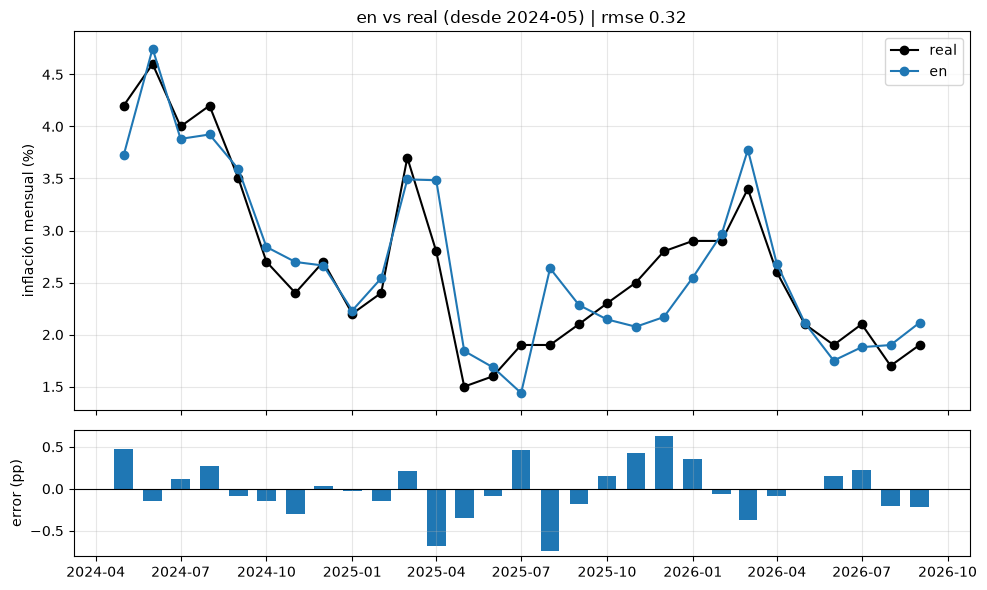

In [34]:
import matplotlib.pyplot as plt

def graficar(col, desde="2024-05"):
    d = resultados.loc[desde:]
    x = d.index.to_timestamp()
    err = d["inflacion"] - d[col]

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})

    ax1.plot(x, d["inflacion"], color="black", marker="o", label="real")
    ax1.plot(x, d[col], color="tab:blue", marker="o", label=col)
    ax1.set_ylabel("inflación mensual (%)")
    ax1.set_title(f"{col} vs real (desde {desde}) | rmse {rmse(err):.2f}")
    ax1.grid(alpha=0.3)
    ax1.legend()

    ax2.bar(x, err, width=20, color="tab:blue")
    ax2.axhline(0, color="black", linewidth=0.8)
    ax2.set_ylabel("error (pp)")
    ax2.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

graficar("en")

## conclusiones del backtest (elastic net, ventana expansiva desde 2022-01)

- elastic net con cv (alpha y l1_ratio elegidos adentro de cada mes con timeseriessplit) tiene rmse 0.70 desde 2022 y 0.32 desde 2024-05
- el rem tiene 0.75 y 0.39, y el random walk 2.57 y 1.00
- le gana por mucho al random walk, pero contra el rem es indistinguible: diebold-mariano t=0.60 (desde 2022) y t=0.88 (desde 2024-05), y gana solo en ~45% de los meses
- la ventaja promedio desde 2022 depende de un solo mes (2024-02): sin ese mes el modelo queda peor que el rem
- el rem pesa mucho mas que el resto en los coeficientes (3.04 vs 0.34 la segunda), asi que el modelo es basicamente el rem corregido con dolar, tasas e inflacion pasada
- el dm es la version simple (errores independientes), con correccion hac daria t aun mas bajo
- lo que se va a publicar: pronostico de precision comparable al rem + intervalo calibrado (aci), no "le gano al rem"
- cuidado con el snooping: solo se probaron dos configuraciones (alpha fijo y cv), la segunda definida antes de ver resultados

In [35]:
# ahora probamos una via alternativa, ya no reemplazar el REM, sino corregirlo con EN utilizando la ventaja informativa

y_error=y-X["rem"]
print(y_error.head())
print(y_error.describe())

mes
2019-01    0.4
2019-02    0.3
2019-03    0.9
2019-04   -0.6
2019-05    0.1
Freq: M, dtype: float64
count    93.000000
mean     -0.084437
std       0.657980
min      -2.600000
25%      -0.400000
50%       0.000000
75%       0.300000
max       1.200000
dtype: float64


In [39]:
# la mediana es cero por lo q el sesgo en promedio es cero, no hay mucho q corregir, probamos:

preds_rem=[]   # lista vacia donde voy guardando el pronostico de cada mes

for mes in meses_test:   # recorro cada mes del backtest (2022-01 en adelante), uno por vuelta
    X_train=X[X.index<mes]   # variables de los meses anteriores a "mes" (para no mirar el futuro)
    e_train=y_error[y_error.index<mes]   # error del rem de esos meses, es lo que el modelo tiene que aprender (en vez de la inflacion)

    modelo=make_pipeline(StandardScaler(), ElasticNetCV(l1_ratio=[0.2, 0.5, 0.8], cv=TimeSeriesSplit(n_splits=5), max_iter=10000))   # primero estandariza las variables, despues elastic net que elige solo alpha y l1_ratio con validacion cruzada hacia adelante, max_iter le da mas vueltas al optimizador para que converja
    modelo.fit(X_train, e_train)   # entrena: busca los coeficientes que mejor predicen el error del rem con las variables

    correccion=modelo.predict(X.loc[[mes]])[0]   # le paso la fila del mes (doble corchete = tabla de 1 fila), me devuelve la correccion y con [0] saco el numero
    preds_rem.append(correccion + X.loc[mes, "rem"])   # pronostico final = rem de ese mes + la correccion, y lo agrego a la lista

resultados["en_rem"]=pd.Series(preds_rem, index=meses_test)   # paso la lista a columna nueva, con las fechas como indice para que alinee por mes

for desde in ["2022-01", "2024-05"]:   # hago dos cortes: backtest completo y desde 2024-05
    d = resultados.loc[desde:]   # me quedo con las filas desde esa fecha hasta el final
    print(desde, "EN:", round(rmse(d["inflacion"] - d["en"]), 2),   # error cuadratico medio del en (real menos pronostico), redondeado a 2 decimales
          "| EN_REM:", round(rmse(d["inflacion"] - d["en_rem"]), 2),   # lo mismo para el elastic net sobre el error del rem
          "| REM:", round(rmse(d["inflacion"] - d["rem"]), 2))   # y para el rem, que es el rival a batir

2022-01 EN: 0.7 | EN_REM: 0.67 | REM: 0.75
2024-05 EN: 0.32 | EN_REM: 0.29 | REM: 0.39


In [45]:
from sklearn.ensemble import RandomForestRegressor

# ahora lo mismo pero con random forest

preds_rf=[]

for mes in meses_test:
    X_train=X[X.index<mes]
    e_train=y_error[y_error.index<mes] # error del rem de esos meses

    modelo=RandomForestRegressor(n_estimators=300, min_samples_leaf=3, max_features=0.5, random_state=0)
    # armo un bosque nuevo en cada vuelta: 300 arboles, hojas con minimo 3 meses, cada pregunta mira la mitad de las variables, semilla fija
    modelo.fit(X_train,e_train) # cada modelo aprende sobre la base de train
    correccion=modelo.predict(X.loc[[mes]])[0]   
    # le paso la fila del mes (tabla de 1 fila x 19 variables, por el doble corchete), predice la correccion y con el 0 saco el numero del array 
    # # (lo encuentra gracias a loc porque mes no es una variable)
    preds_rf.append(correccion+X.loc[mes, "rem"]) # la pred es el rem del mes + la correcc

resultados["rf_rem"]=pd.Series(preds_rf, index=meses_test) # paso la lista a una columna nueva, con los meses como indice para que alinee por fecha

for desde in ["2022-01","2024-05"]: # lo repito para un periodo largo y uno mas corto
    d=resultados.loc[desde:] # usamos los resultados desde esa fecha en adelante (h el final)
    print(desde, "EN_REM:", round(rmse(d["inflacion"]-d["en_rem"]),2), # para cada uno de esos periodos, el rmse q sale de inf posta - la predecida al cuad
          "| RF_REM:", round(rmse(d["inflacion"]-d["rf_rem"]),2),
          "| REM:", round(rmse(d["inflacion"]-d["rem"]),2))
    


2022-01 EN_REM: 0.67 | RF_REM: 0.64 | REM: 0.75
2024-05 EN_REM: 0.29 | RF_REM: 0.29 | REM: 0.39


In [46]:
resultados["prom"]=resultados[["en","en_rem","rf_rem"]].mean(axis=1)   # promedio de los 3 pronosticos, mes por mes (axis=1 = por fila, entre columnas)

for desde in ["2022-01","2024-05"]:   # los dos periodos de siempre: largo y reciente
    d=resultados.loc[desde:]   # recorto desde esa fecha en adelante
    print(desde, "EN:", round(rmse(d["inflacion"]-d["en"]),2),   # rmse de cada modelo: error = real menos pronostico
          "| EN_REM:", round(rmse(d["inflacion"]-d["en_rem"]),2),
          "| RF_REM:", round(rmse(d["inflacion"]-d["rf_rem"]),2),
          "| PROM:", round(rmse(d["inflacion"]-d["prom"]),2),
          "| REM:", round(rmse(d["inflacion"]-d["rem"]),2))

2022-01 EN: 0.7 | EN_REM: 0.67 | RF_REM: 0.64 | PROM: 0.65 | REM: 0.75
2024-05 EN: 0.32 | EN_REM: 0.29 | RF_REM: 0.29 | PROM: 0.27 | REM: 0.39


In [47]:
for desde in ["2022-01","2024-05"]:   # los dos periodos de siempre
    d=resultados.loc[desde:]   # recorto desde esa fecha en adelante
    dif=(d["inflacion"]-d["rem"])**2 - (d["inflacion"]-d["prom"])**2   # error al cuadrado del rem menos el del promedio: positivo = ese mes gano el promedio
    t=dif.mean()/(dif.std()/len(dif)**0.5)   # ventaja promedio dividida por su error estandar: cuantos "desvios" esta lejos de cero (necesito mas de ~2)
    print(desde, "| ventaja media:", round(dif.mean(),3),   # cuanto mejor es el promedio en error cuadrado
          "| meses que gana:", round((dif>0).mean(),2),   # proporcion de meses en que el promedio le gano al rem
          "| t:", round(t,2),   # el estadistico
          "| mes que mas aporta:", dif.idxmax(), round(dif.max(),2))   # el mes con mayor ventaja, para ver si todo depende de uno solo

2022-01 | ventaja media: 0.142 | meses que gana: 0.47 | t: 1.53 | mes que mas aporta: 2024-02 4.0
2024-05 | ventaja media: 0.076 | meses que gana: 0.48 | t: 1.54 | mes que mas aporta: 2025-03 1.0


## conclusiones del backtest (ventana expansiva desde 2022-01)

modelos probados (rmse desde 2022-01 / desde 2024-05):
- elastic net con cv sobre la inflacion: 0.70 / 0.32
- elastic net con cv sobre el error del rem (corrige al rem con las variables): 0.67 / 0.29
- random forest sobre el error del rem: 0.64 / 0.29
- promedio simple de los tres: 0.65 / 0.27
- rem: 0.75 / 0.39
- random walk: 2.57 / 1.00

lo que sale de esto:
- todos le ganan por mucho al random walk, asi que las variables aportan
- sobre el rem la ventaja es chica: el promedio tiene un 31% menos de error desde 2024-05 (0.27 vs 0.39)
- diebold-mariano del promedio contra el rem: t=1.53 (desde 2022) y t=1.54 (desde 2024-05), no es significativo al 5%
- el promedio le gana al rem en solo 47-48% de los meses, la ventaja viene de pocos meses grandes (2024-02 explica casi la mitad en el periodo largo y 2025-03 casi la mitad en el reciente)
- el dm es la version simple (errores independientes), con correccion hac el t seria algo menor
- no se puede decir que le gano al rem, si que tiene menor error en el backtest con diferencia no significativa

decisiones tomadas de antemano (para no hacer snooping):
- el pronostico que se publica es el promedio de los tres, no el mejor del backtest
- hiperparametros del random forest fijos, no tuneados mirando el resultado
- quedaron afuera lightgbm, extra trees y proceso gaussiano para una segunda version

antecedente: forte (bbva research, 2024) usa random forest para el mismo problema y tambien encuentra precision similar al rem